<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

# --------------------------------
# Load Dataset
# --------------------------------

df = pd.read_csv("/content/drive/MyDrive/ML/lie_dataset_100.csv")

print("First 5 rows of dataset:")
print(df.head())


# --------------------------------
# Separate Input and Output
# --------------------------------

X = df[
    [
        "response_time",
        "heart_rate",
        "hesitation_score",
        "stress_level"
    ]
].values

y = df["lie"].values


# --------------------------------
# Train-Test Split
# --------------------------------

train_size = int(0.8 * len(X))

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]


# --------------------------------
# Feature Scaling
# --------------------------------

X_mean = np.mean(X_train, axis=0)
X_std = np.std(X_train, axis=0)

# Avoid division by zero
X_std[X_std == 0] = 1

X_train = (X_train - X_mean) / X_std
X_test = (X_test - X_mean) / X_std


# --------------------------------
# Add Bias
# --------------------------------

X_train = np.c_[
    np.ones(X_train.shape[0]),
    X_train
]

X_test = np.c_[
    np.ones(X_test.shape[0]),
    X_test
]


# --------------------------------
# Initialize Weights
# --------------------------------

weights = np.zeros(X_train.shape[1])

learning_rate = 0.01
epochs = 10000


# --------------------------------
# Sigmoid Function
# --------------------------------

def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# --------------------------------
# Logistic Regression
# --------------------------------

for i in range(epochs):

    # Linear equation
    z = np.dot(X_train, weights)

    # Convert to probability
    y_pred = sigmoid(z)

    # Calculate error
    error = y_pred - y_train

    # Calculate gradient
    gradient = (
        1 / len(X_train)
    ) * np.dot(X_train.T, error)

    # Update weights
    weights = weights - learning_rate * gradient


# --------------------------------
# Test Prediction
# --------------------------------

z_test = np.dot(X_test, weights)

probability = sigmoid(z_test)


# --------------------------------
# Convert Probability into Class
# --------------------------------

y_pred_test = (probability >= 0.5).astype(int)


# --------------------------------
# Display Results
# --------------------------------

print("\nActual Lie:")
print(y_test)

print("\nPredicted Lie:")
print(y_pred_test)

print("\nPrediction Probability:")
print(probability)


# --------------------------------
# Calculate Accuracy
# --------------------------------

correct = np.sum(y_test == y_pred_test)

accuracy = correct / len(y_test)

print("\nAccuracy:", accuracy * 100, "%")

First 5 rows of dataset:
   response_time  heart_rate  hesitation_score  stress_level  lie
0           3.86          80                64            62    1
1           2.41          62                16            35    0
2           1.72          66                39             1    0
3           2.28         103                78            79    1
4           3.39          83                 5            21    0

Actual Lie:
[0 0 0 0 1 0 1 1 0 0 1 0 1 1 0 1 1 0 1 1]

Predicted Lie:
[0 0 0 0 1 0 1 1 0 0 1 0 1 1 0 1 1 0 1 1]

Prediction Probability:
[5.31308761e-04 1.40570472e-02 4.02868927e-03 1.12239326e-02
 9.99655050e-01 1.26555090e-02 9.98079980e-01 9.99854418e-01
 2.02841236e-03 9.99773061e-04 9.96793761e-01 1.00112954e-02
 9.66726833e-01 9.98540731e-01 1.04560115e-04 9.92585999e-01
 9.55992441e-01 8.74564436e-04 5.04946043e-01 9.97631925e-01]

Accuracy: 100.0 %


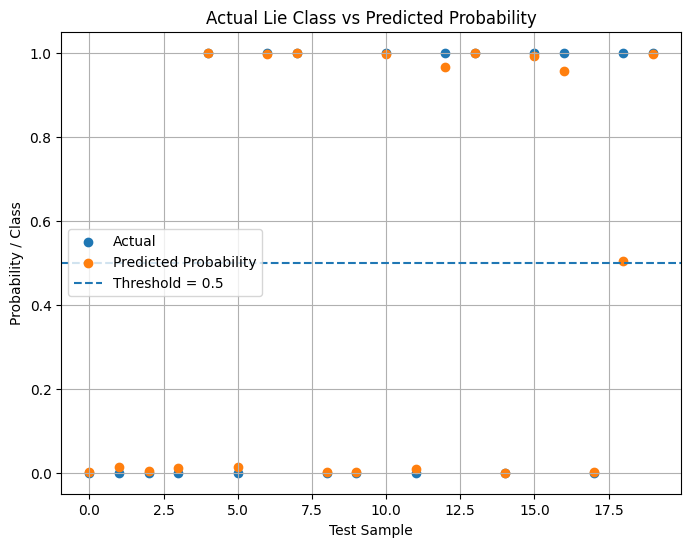

In [ ]:
# --------------------------------
# Graph: Actual vs Prediction Probability
# --------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    range(len(y_test)),
    y_test,
    label="Actual"
)

plt.scatter(
    range(len(y_test)),
    probability,
    label="Predicted Probability"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel("Test Sample")
plt.ylabel("Probability / Class")
plt.title("Actual Lie Class vs Predicted Probability")

plt.legend()
plt.grid(True)
plt.show()